In [1]:
import openpyxl
import pyomo.environ as pe
import numpy as np
import os
import pandas as pd
from datetime import datetime
from datetime import timedelta
import matplotlib.pyplot as plt


# Caracterização W

In [2]:
Year=2019
Month=2
Day=14
N_DEV = 13

# instante inicial e final do dia em análise
day_start_dt = datetime(Year, Month, Day, 0, 0, 0)
day_end_dt = day_start_dt + timedelta(days=1)

# =========================
# DEVICE GROUPS
# =========================
BUFFERED_DEVICES = {0, 2}        # Drinks Refrigerator, Garde Manger
OPERATIONAL_DEVICES = {1, 3, 4, 5, 6}  # Blast Chiller, Ice Machine, Dual Fryer, Salamander, Infrared Shelf
NON_FLEXIBLE_DEVICES = {7, 8, 9}  # Glass Washer, Dish Washer, Convection Oven
POWER_FLEXIBLE_DEVICES = {10, 11, 12}  # Light1, Light2, Exhaust
EXTERNAL_PROFILE_DEVICES = {12}  # Exhaust

POWER_FLEXIBLE_SCHEDULES = {
    10: {
        "name": "Light1",
        "start": 10 * 60,          # 10:00
        "end": 22 * 60 + 30        # 22:30
    },
    11: {
        "name": "Light2",
        "start": 10 * 60,          # 10:00
        "end": 22 * 60 + 30        # 22:30
    }
}
EXTERNAL_PROFILE_DATES = {
    12: "2019-03-11"
}

N_MIN_ACTIVATIONS = 2
T_NO_ACTIVITY_FALLBACK = 5000
T_MIN = 5
T_OFF_FORCED_ON = 5
DAY_MINUTES = 24 * 60
T= DAY_MINUTES

# diretório dos ficheiros
diretorio = '/Users/luismartins/Desktop/Tese/Tese_repository/Data'

# mapeamento appliance -> ficheiro de ativações
activation_files = {
    0: "activations_Drinks_Refrigerator.csv",
    1: "activations_Blast_Chiller.csv",
    2: "activations_Garde_Manger_10.csv",
    3: "activations_Ice_Machine.csv",
    4: "activations_Dual_Fryer.csv",
    5: "activations_Salamander_1.csv",
    6: "activations_Infrared_Shelf.csv",
    7: "activations_Glass_Washer.csv",
    8: "activations_Dish_Washer.csv",
    9: "activations_Convection_Oven_1.csv",
}
external_activation_files = {
    12: "05_Exhaust_activations.xlsx"
}



In [3]:
# ======================================
# LEITURA DO INFO.XLSX
# ======================================

df_info = pd.read_excel('/Users/luismartins/Desktop/Tese/Tese_repository/Code/RT24 Max Utility/Info_RT24.xlsx')

print("Colunas do Info.xlsx:")
print(df_info.columns.tolist())

# se quiseres confirmar o número de equipamentos do Excel
print("\nNúmero de linhas no Info.xlsx:", len(df_info))

# opcional: garantir consistência
if len(df_info) != N_DEV:
    raise ValueError(f"N_DEV={N_DEV}, mas o Info.xlsx tem {len(df_info)} linhas.")

# parâmetros por equipamento
dev_names = df_info["Dev"].tolist()

# índice do tipo de flexibilidade
Type = df_info["Type"].to_numpy(dtype=int)

# estado inicial
# para já vamos ler do Excel; mais tarde podes forçar a zero ou atualizar dinamicamente
State_Init = df_info["State_Init"].to_numpy(dtype=int)

# potência máxima
Power_max = df_info["Power_max"].to_numpy(dtype=float)

# pesos da componente de potência
Weight_P_max = df_info["Weight_P_max"].to_numpy(dtype=float)
Weight_P_min = df_info["Weight_P_min"].to_numpy(dtype=float)

# percentagens de potência
# MUITO IMPORTANTE: converter de % para fração
Y_max = df_info["Y_max (%)"].to_numpy(dtype=float) / 100.0
Y_min = df_info["Y_min (%)"].to_numpy(dtype=float) / 100.0

# tempo mínimo para manter alteração de potência
TimeHoldPower = df_info["TimeHoldPower"].to_numpy(dtype=float)

# impressão de controlo
print("\nResumo dos equipamentos:")
for j in range(N_DEV):
    print(
        f"{j}: {dev_names[j]} | "
        f"Type={Type[j]} | "
        f"State_Init={State_Init[j]} | "
        f"Pmax={Power_max[j]} | "
        f"Ymin={Y_min[j]} | "
        f"Ymax={Y_max[j]}"
        f" | TimeHoldPower={TimeHoldPower[j]}"
    )

Colunas do Info.xlsx:
['Dev', 'j', 'Type', 'State_Init', 'Power_max', 'Weight_P_max', 'Weight_P_min', 'Y_max (%)', 'Y_min (%)', 'TimeHoldPower']

Número de linhas no Info.xlsx: 13

Resumo dos equipamentos:
0: Drinks Refrigerator | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
1: Blast Chiller | Type=2 | State_Init=0 | Pmax=1500.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
2: Garde Manger | Type=2 | State_Init=0 | Pmax=1000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
3: Ice Machine | Type=2 | State_Init=0 | Pmax=400.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
4: Dual Fryer | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
5: Salamander | Type=2 | State_Init=0 | Pmax=3000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
6: Infrared Shelf | Type=2 | State_Init=0 | Pmax=800.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
7: Glass Washer | Type=0 | State_Init=0 | Pmax=1600.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
8: Dish Washer 

In [4]:
def minute_of_day(ts):
    m = ts.hour * 60 + ts.minute
    if ts.second >= 30:
        m += 1
    return min(m, 1439)

def get_time_zone(minute):
    """
    0 -> 00:00 - 09:59
    1 -> 10:00 - 19:29
    2 -> 19:30 - 22:29
    3 -> 22:30 - 23:59
    """
    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3

def load_activation_day_csv(diretorio, nome_do_arquivo, target_date):
    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)
    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_csv(caminho_arquivo, sep=';').iloc[:, 0:3].copy()

    df["first_min_on"] = pd.to_datetime(df["first_min_on"], utc=True, errors="coerce")
    df["last_min_on"]  = pd.to_datetime(df["last_min_on"],  utc=True, errors="coerce")

    df["first_min_on"] = df["first_min_on"].dt.tz_convert(None)
    df["last_min_on"]  = df["last_min_on"].dt.tz_convert(None)

    df = df.dropna(subset=["first_min_on", "last_min_on"]).sort_values("first_min_on").reset_index(drop=True)

    target_date = pd.to_datetime(target_date).date()
    df_day = df[df["first_min_on"].dt.date == target_date].copy().reset_index(drop=True)

    return df_day

def build_X_day_for_device(j, nome_do_arquivo, diretorio, target_date, X_day):
    """
    Constrói X_day[:, j] para o dia inteiro.
    """
    X_day[:, j] = 0

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end   = minute_of_day(row["last_min_on"])

        if end >= start:
            X_day[start:end + 1, j] = 1
        else:
            X_day[start:1440, j] = 1
            X_day[0:end + 1, j] = 1

def compute_operational_ton_toff_day(j, nome_do_arquivo, diretorio, target_date):
    """
    Operational devices:
    T_ON/T_OFF por timezone, avaliando presença ON dentro da timezone,
    mesmo quando a ativação começou antes da timezone.

    Regras:
      - se não há minutos ON na timezone:
            T_ON  = T_NO_ACTIVITY_FALLBACK
            T_OFF = T_NO_ACTIVITY_FALLBACK

      - se há minutos ON na timezone:
            T_ON = duração total ON dentro da timezone, ou mediana dos blocos ON na timezone

            se houver gaps OFF observados:
                T_OFF = mediana dos gaps OFF
            senão:
                T_OFF = T_OFF_FORCED_ON
    """

    T_ON_day_j = np.full(DAY_MINUTES, T_NO_ACTIVITY_FALLBACK, dtype=int)
    T_OFF_day_j = np.full(DAY_MINUTES, T_NO_ACTIVITY_FALLBACK, dtype=int)

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return T_ON_day_j, T_OFF_day_j

    # construir X_day do device
    X_dev = np.zeros(DAY_MINUTES, dtype=int)

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end = minute_of_day(row["last_min_on"])

        if end >= start:
            X_dev[start:end + 1] = 1
        else:
            X_dev[start:DAY_MINUTES] = 1
            X_dev[0:end + 1] = 1

    zone_limits = {
        0: (0, 600),       # 00:00 - 09:59
        1: (600, 1170),   # 10:00 - 19:29
        2: (1170, 1350),  # 19:30 - 22:29
        3: (1350, 1440),  # 22:30 - 23:59
    }

    zone_ton = {}
    zone_toff = {}

    for z, (start_z, end_z) in zone_limits.items():
        X_zone = X_dev[start_z:end_z]

        on_minutes = int(np.sum(X_zone))

        # sem presença ON na timezone
        if on_minutes == 0:
            zone_ton[z] = T_NO_ACTIVITY_FALLBACK
            zone_toff[z] = T_NO_ACTIVITY_FALLBACK
            continue

        # há presença ON na timezone
        # calcular blocos ON e OFF dentro da timezone
        on_blocks = []
        off_blocks = []

        current_state = X_zone[0]
        count = 1

        for val in X_zone[1:]:
            if val == current_state:
                count += 1
            else:
                if current_state == 1:
                    on_blocks.append(count)
                else:
                    off_blocks.append(count)

                current_state = val
                count = 1

        # fechar último bloco
        if current_state == 1:
            on_blocks.append(count)
        else:
            off_blocks.append(count)

        # T_ON: se há blocos ON, usa mediana dos blocos ON
        if len(on_blocks) > 0:
            ton_z = max(1, int(np.median(on_blocks)))
        else:
            ton_z = T_NO_ACTIVITY_FALLBACK

        # T_OFF:
        # só usar gaps OFF se existirem dentro da zona
        # se está sempre ON ou sem OFF observado, usar forced-on
        valid_off_blocks = [b for b in off_blocks if b > 0]

        if len(valid_off_blocks) > 0:
            toff_z = max(1, int(np.median(valid_off_blocks)))
        else:
            toff_z = T_OFF_FORCED_ON

        zone_ton[z] = ton_z
        zone_toff[z] = toff_z

    for t in range(DAY_MINUTES):
        z = get_time_zone(t)
        T_ON_day_j[t] = zone_ton[z]
        T_OFF_day_j[t] = zone_toff[z]
        
    return T_ON_day_j, T_OFF_day_j

def compute_buffered_ton_toff_for_window(j, X_window):
    """
    Buffered devices:
    Replica a lógica da Ana dentro da janela de 60 min.
    """
    T_ON_window_j = np.zeros(T, dtype=int)
    T_OFF_window_j = np.zeros(T, dtype=int)

    cont_on = 0
    cont_off = 0
    periodo = 0
    first = 0

    for i in range(T):
        if i == 0 and X_window[i] == 0:
            first = 0

        if X_window[i] == 0:
            cont_off += 1

        if X_window[i] == 1:
            cont_on += 1

        if X_window[i] == 1 and i < T - 1 and X_window[i + 1] == 0:
            periodo = i
            for k in range(first, periodo + 1):
                T_OFF_window_j[k] = max(1, cont_off)
                T_ON_window_j[k] = max(1, cont_on)

            cont_on = 1
            cont_off = 1
            first = periodo + 1

        elif X_window[i] == 1 and i == T - 1:
            for k in range(first, T):
                T_OFF_window_j[k] = max(1, cont_off)
                T_ON_window_j[k] = max(1, cont_on)

        else:
            if i == T - 1:
                for k in range(first, T):
                    if X_window[i] == 1:
                        T_ON_window_j[k] = max(1, cont_on)
                        T_OFF_window_j[k] = max(1, T_ON_window_j[k])
                    else:
                        T_OFF_window_j[k] = max(1, cont_off - 1)
                        T_ON_window_j[k] = max(1, T_OFF_window_j[k])

    T_ON_window_j[T_ON_window_j <= 0] = 1
    T_OFF_window_j[T_OFF_window_j <= 0] = 1

    return T_ON_window_j, T_OFF_window_j

def build_X_day_all_devices(day_start_dt, activation_files, diretorio):
    X_day = np.zeros((DAY_MINUTES, N_DEV), dtype=int)
    target_date = day_start_dt.date()

    for j in range(N_DEV):
        build_X_day_for_device(
            j=j,
            nome_do_arquivo=activation_files[j],
            diretorio=diretorio,
            target_date=target_date,
            X_day=X_day
        )

    return X_day

def build_power_flexible_schedule(T, start_minute, end_minute):
    x = np.zeros(T, dtype=int)

    if end_minute > start_minute:
        x[start_minute:end_minute] = 1
    else:
        # caso atravesse meia-noite
        x[start_minute:T] = 1
        x[0:end_minute] = 1

    return x


def get_power_flexible_ton_toff(T, start_minute, end_minute):
    if end_minute > start_minute:
        on_duration = end_minute - start_minute
    else:
        on_duration = (T - start_minute) + end_minute

    off_duration = T - on_duration

    T_ON_j = np.full(T, max(on_duration, 1), dtype=int)
    T_OFF_j = np.full(T, max(off_duration, 1), dtype=int)

    return T_ON_j, T_OFF_j

def build_external_profile_from_activation_file(
    diretorio,
    nome_do_arquivo,
    target_date,
    T=1440
):

    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)

    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_excel(caminho_arquivo).iloc[:, 0:3].copy()

    df.columns = df.columns.str.strip()

    df["First_min_on"] = pd.to_datetime(
        df["First_min_on"],
        utc=True,
        errors="coerce"
    )

    df["Last_min_on"] = pd.to_datetime(
        df["Last_min_on"],
        utc=True,
        errors="coerce"
    )

    df["First_min_on"] = df["First_min_on"].dt.tz_convert(None)
    df["Last_min_on"] = df["Last_min_on"].dt.tz_convert(None)

    # IMPORTANTÍSSIMO
    target_date = pd.to_datetime(target_date).date()

    df = df[
        df["First_min_on"].dt.date == target_date
    ].copy()

    x = np.zeros(T, dtype=int)

    for _, row in df.iterrows():

        start = minute_of_day(row["First_min_on"])
        end = minute_of_day(row["Last_min_on"])

        if end >= start:
            x[start:end + 1] = 1
        else:
            x[start:T] = 1
            x[0:end + 1] = 1

    return x

In [5]:
# 1) Construir X_day global apenas para devices com ficheiro
X_day = np.zeros((T, N_DEV), dtype=int)

for j, nome_do_arquivo in activation_files.items():
    build_X_day_for_device(
        j=j,
        nome_do_arquivo=nome_do_arquivo,
        diretorio=diretorio,
        target_date=day_start_dt.date(),
        X_day=X_day
    )

# 2) Inicializar matrizes
X_onoff_FC_matrix = np.zeros((T, N_DEV), dtype=int)
T_ON_FC_matrix = np.ones((T, N_DEV), dtype=int)
T_OFF_FC_matrix = np.ones((T, N_DEV), dtype=int)

target_date = day_start_dt.date()

# 3) Preencher baseline com ativações reais
X_onoff_FC_matrix[:, :] = X_day[:T, :]

# 4) Adicionar devices power-flexible simulados
for j in POWER_FLEXIBLE_DEVICES:

    # só os que têm horário definido manualmente
    if j not in POWER_FLEXIBLE_SCHEDULES:
        continue

    sched = POWER_FLEXIBLE_SCHEDULES[j]

    X_onoff_FC_matrix[:, j] = build_power_flexible_schedule(
        T=T,
        start_minute=sched["start"],
        end_minute=sched["end"]
    )
# 4.5) Adicionar perfis externos
for j in EXTERNAL_PROFILE_DEVICES:

    X_onoff_FC_matrix[:, j] = build_external_profile_from_activation_file(
        diretorio=diretorio,
        nome_do_arquivo=external_activation_files[j],
        target_date=EXTERNAL_PROFILE_DATES[j],
        T=T
    )
    
# =========================
# BUILD Y_FC_MATRIX
# =========================

Y_FC_matrix = np.zeros((T, N_DEV), dtype=float)

for j in range(N_DEV):

    if Type[j] == 1:  # power-flexible
        Y_FC_matrix[:, j] = X_onoff_FC_matrix[:, j] * Y_max[j]

    else:
        # Para devices não power-flexible, Y não é relevante.
        # Mas pode ficar igual a X para manter consistência.
        Y_FC_matrix[:, j] = X_onoff_FC_matrix[:, j]
        

# 5) Construir T_ON / T_OFF
for j in range(N_DEV):
    
    if j in POWER_FLEXIBLE_DEVICES:

        if j in POWER_FLEXIBLE_SCHEDULES:

            sched = POWER_FLEXIBLE_SCHEDULES[j]
            T_ON_j, T_OFF_j = get_power_flexible_ton_toff(
                T=T,
                start_minute=sched["start"],
                end_minute=sched["end"]
            )
        elif j in EXTERNAL_PROFILE_DEVICES:
            on_minutes = int(np.sum(X_onoff_FC_matrix[:, j]))
            off_minutes = T - on_minutes
            T_ON_j = np.full(T, max(on_minutes, 1), dtype=int)
            T_OFF_j = np.full(T, max(off_minutes, 1), dtype=int)
        else:
            T_ON_j = np.ones(T, dtype=int)
            T_OFF_j = np.ones(T, dtype=int)

    elif j in BUFFERED_DEVICES:
        T_ON_j, T_OFF_j = compute_buffered_ton_toff_for_window(
            j,
            X_onoff_FC_matrix[:, j]
        )

    elif j in OPERATIONAL_DEVICES:
        nome_do_arquivo = activation_files[j]

        T_ON_j, T_OFF_j = compute_operational_ton_toff_day(
            j=j,
            nome_do_arquivo=nome_do_arquivo,
            diretorio=diretorio,
            target_date=target_date
        )

    else:
        T_ON_j = np.ones(T, dtype=int)
        T_OFF_j = np.ones(T, dtype=int)

    T_ON_FC_matrix[:, j] = T_ON_j
    T_OFF_FC_matrix[:, j] = T_OFF_j

In [6]:
for j in BUFFERED_DEVICES:
    print(f"\nBuffered device {j} - first minutes")
    print("T_ON :", T_ON_FC_matrix[13*60:14*60, j])
    print("T_OFF:", T_OFF_FC_matrix[13*60:14*60, j])

for j in OPERATIONAL_DEVICES:
    print(f"\nOperational device {j} - first minutes")
    print("T_ON :", T_ON_FC_matrix[:60, j])
    print("T_OFF:", T_OFF_FC_matrix[:60, j])
    
for j in POWER_FLEXIBLE_DEVICES:
    print("X 10:00-10:10:", X_onoff_FC_matrix[14*60+45:14*60+50, j])
    print("X 22:25-22:35:", X_onoff_FC_matrix[22*60+25:22*60+35, j])
    print("T_ON :", T_ON_FC_matrix[10*60:10*60+5, j])
    print("T_OFF:", T_OFF_FC_matrix[10*60:10*60+5, j])
    
j = 12

print(external_activation_files[j])
print("ON minutes:", X_onoff_FC_matrix[:, j].sum())

on_idx = np.where(X_onoff_FC_matrix[:, j] == 1)[0]
print("First ON:", f"{on_idx[0]//60:02d}:{on_idx[0]%60:02d}")
print("Last ON :", f"{on_idx[-1]//60:02d}:{on_idx[-1]%60:02d}")


Buffered device 0 - first minutes
T_ON : [31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31
 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 31 34 34
 34 34 34 34 34 34 34 34 34 34 34 34]
T_OFF: [ 62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62
  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62  62
  62  62  62  62  62  62  62  62  62  62 109 109 109 109 109 109 109 109
 109 109 109 109 109 109]

Buffered device 2 - first minutes
T_ON : [6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6
 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6]
T_OFF: [22 22 22 22 22 22 22 22 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25
 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25 25
 25 25 25 25 25 25 25 25 25 25 25 25]

Operational device 1 - first minutes
T_ON : [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000 5000 5000 5000 5000
 5000 5000 5000 5000 5000 5000 5000 5000 5000 5000

In [7]:
def compute_time_weight(X, T_ON, T_OFF):
    """
    Computes W(t) according to the paper.

    Parameters
    ----------
    X : ndarray (1440,)
        Binary appliance state.

    T_ON : ndarray (1440,)
    T_OFF : ndarray (1440,)

    Returns
    -------
    W : ndarray (1440,)
    """

    T = len(X)

    W = np.zeros(T)

    # ---------- Initialization ----------

    if X[0] == 0:
        W[0] = 1 + 9 / T_OFF[0]
    else:
        W[0] = 10 - 9 / T_ON[0]

    # ---------- Evolution ----------

    for t in range(1, T):

        if X[t] == 0:

            W[t] = W[t-1] + 9 / T_OFF[t]

        else:

            W[t] = W[t-1] - 9 / T_ON[t]

        W[t] = np.clip(W[t], 1, 10)

    return W

def compute_power_weight(Y, Y_min, Y_max, W_P_min, W_P_max, m=1e-6):
    Y_safe = np.clip(Y, Y_min, Y_max)

    WP = W_P_min + ((W_P_max - W_P_min) * (Y_safe - Y_min)) / (
        (Y_max - Y_min) + m
    )

    return np.clip(WP, min(W_P_min, W_P_max), max(W_P_min, W_P_max))

WT_FC_matrix = np.zeros((T, N_DEV))
WP_FC_matrix = np.zeros((T, N_DEV))

for j in range(N_DEV):

    if Type[j] == 2:  # time-flexible
        WT_FC_matrix[:, j] = compute_time_weight(
            X_onoff_FC_matrix[:, j],
            T_ON_FC_matrix[:, j],
            T_OFF_FC_matrix[:, j]
        )

    elif Type[j] == 1:  # power-flexible
        WP_j = compute_power_weight(
            Y_FC_matrix[:, j],
            Y_min[j],
            Y_max[j],
            Weight_P_min[j],
            Weight_P_max[j]
        )
        WP_FC_matrix[:, j] = np.where(
            X_onoff_FC_matrix[:, j] == 1,
            WP_j,
            np.nan
        )

In [8]:
print("Matriz peso, WP_FC_matrix:")
print(WP_FC_matrix[1000])
print("Y atual:")
print(Y_FC_matrix[1000])
print("Y_min:")
print(Y_min[12])

Matriz peso, WP_FC_matrix:
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         3.999994   2.99999857
 9.99998714]
Y atual:
[0. 0. 0. 1. 0. 1. 0. 1. 0. 0. 1. 1. 1.]
Y_min:
0.3


In [9]:
for j in POWER_FLEXIBLE_DEVICES:

    print("----------------------------------")
    print(dev_names[j])

    print("Weight_P_min =", Weight_P_min[j])
    print("Weight_P_max =", Weight_P_max[j])

    print("Y_min =", Y_min[j])
    print("Y_max =", Y_max[j])

    print("Y atual =", Y_FC_matrix[1000, j])

    print("WP =", WP_FC_matrix[1000, j])

----------------------------------
Light1
Weight_P_min = 1.0
Weight_P_max = 4.0
Y_min = 0.5
Y_max = 1.0
Y atual = 1.0
WP = 3.999994000012
----------------------------------
Light2
Weight_P_min = 2.0
Weight_P_max = 3.0
Y_min = 0.3
Y_max = 1.0
Y atual = 1.0
WP = 2.9999985714306123
----------------------------------
Exhaust
Weight_P_min = 1.0
Weight_P_max = 10.0
Y_min = 0.3
Y_max = 1.0
Y atual = 1.0
WP = 9.99998714287551


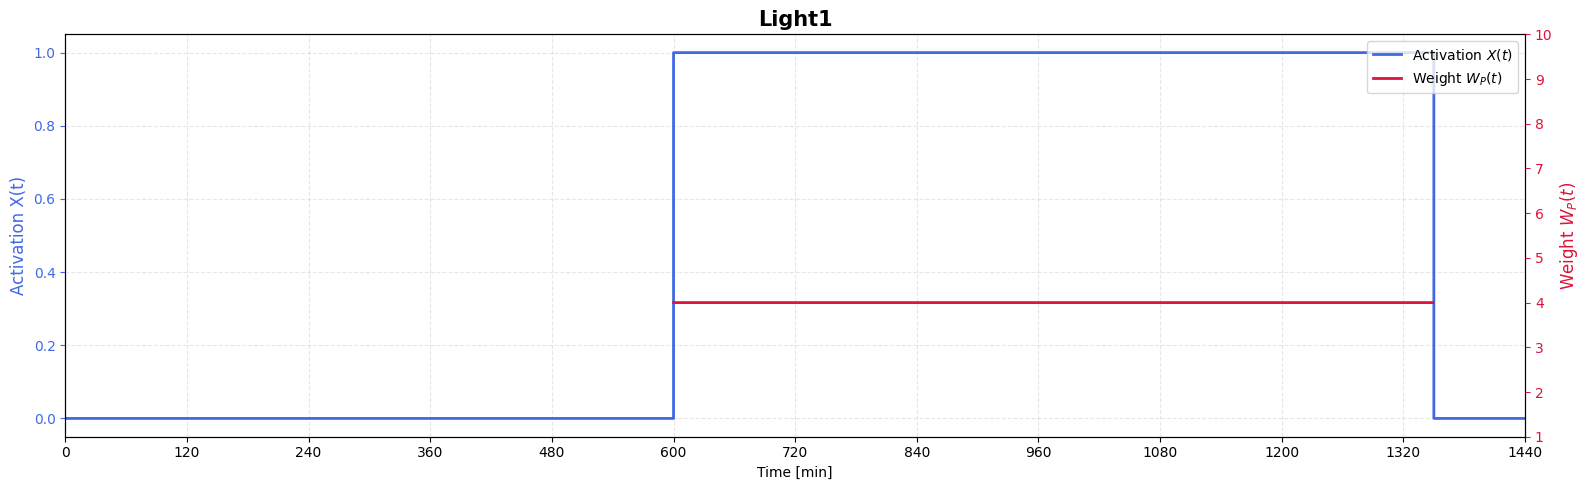

In [10]:
def plot_weight_and_activation(j, dev_names=None):

    t = np.arange(T)

    fig, ax1 = plt.subplots(figsize=(16,5))

    # ---------- Activation ----------
    ax1.step(
        t,
        Y_FC_matrix[:, j],
        where='post',
        color='royalblue',
        linewidth=2,
        label='Activation $X(t)$'
    )

    ax1.set_ylabel("Activation X(t)", color='royalblue', fontsize=12)
    ax1.tick_params(axis='y', colors='royalblue')
    ax1.set_ylim(-0.05,1.05)

    # ---------- Weight ----------
    ax2 = ax1.twinx()

    ax2.plot(
        t,
        WP_FC_matrix[:, j],
        color='crimson',
        linewidth=2,
        label='Weight $W_P(t)$'
    )

    ax2.set_ylabel("Weight $W_P(t)$", color='crimson', fontsize=12)
    ax2.tick_params(axis='y', colors='crimson')
    ax2.set_ylim(1,10)

    # ---------- X axis ----------
    ax1.set_xlabel("Time [min]")
    ax1.set_xlim(0,1440)

    ax1.set_xticks(np.arange(0,1441,120))

    # ---------- Grid ----------
    ax1.grid(True, linestyle='--', alpha=0.3)

    # ---------- Title ----------
    if dev_names is None:
        title = f"Device {j}"
    else:
        title = f"{dev_names[j]}"

    plt.title(title, fontsize=15, weight='bold')

    # ---------- Legend ----------
    l1,lbl1 = ax1.get_legend_handles_labels()
    l2,lbl2 = ax2.get_legend_handles_labels()

    ax1.legend(
        l1+l2,
        lbl1+lbl2,
        loc='upper right'
    )

    plt.tight_layout()
    plt.show()


# Exemplo
plot_weight_and_activation(10, dev_names)

# Caracterização da Flexibilidade

In [11]:
# =========================
# FLEXIBILITY FORECAST
# =========================

BLOCK_SIZE = 15
N_BLOCKS = T // BLOCK_SIZE

TIME_FLEXIBLE_DEVICES = set(np.where(Type == 2)[0])
POWER_FLEXIBLE_DEVICES = set(np.where(Type == 1)[0])
NON_FLEXIBLE_DEVICES = set(np.where(Type == 0)[0])

# =========================
# NORMALIZED WEIGHTS
# =========================

Wbar_T = np.zeros((T, N_DEV), dtype=float)
Wbar_P = np.zeros((T, N_DEV), dtype=float)

# Time-flexible normalization
for j in TIME_FLEXIBLE_DEVICES:
    Wbar_T[:, j] = (WT_FC_matrix[:, j] - 1) / 9

Wbar_T = np.clip(Wbar_T, 0, 1)

# Power-flexible normalization
for j in POWER_FLEXIBLE_DEVICES:
    denom = Weight_P_max[j] - Weight_P_min[j]

    if abs(denom) < 1e-9:
        Wbar_P[:, j] = 0
    else:
        Wbar_P[:, j] = (WP_FC_matrix[:, j] - Weight_P_min[j]) / denom

Wbar_P = np.clip(Wbar_P, 0, 1)

# =========================
# INITIALIZE MATRICES
# =========================

# Time-flexible indices
I_T_up = np.zeros((T, N_DEV))
I_T_down = np.zeros((T, N_DEV))

AI_T_up = np.zeros((N_BLOCKS, N_DEV))
AI_T_down = np.zeros((N_BLOCKS, N_DEV))

RF_T_up = np.zeros((N_BLOCKS, N_DEV))      # W.min
RF_T_down = np.zeros((N_BLOCKS, N_DEV))    # W.min

DC = np.zeros((N_BLOCKS, N_DEV))

# Power-flexible indices
I_P_up = np.zeros((T, N_DEV))
I_P_down = np.zeros((T, N_DEV))

AI_P_up = np.zeros((N_BLOCKS, N_DEV))
AI_P_down = np.zeros((N_BLOCKS, N_DEV))

RF_P_up = np.zeros((N_BLOCKS, N_DEV))      # W.min
RF_P_down = np.zeros((N_BLOCKS, N_DEV))    # W.min

Y_base = np.zeros((N_BLOCKS, N_DEV))

# =========================
# COMPUTE FLEXIBILITY
# =========================

# =========================
# COMPUTE FLEXIBILITY
# =========================

for j in range(N_DEV):

    Xj = X_onoff_FC_matrix[:, j]

    # -------------------------
    # TIME-FLEXIBLE DEVICES
    # -------------------------
    if Type[j] == 2:

        I_T_up[:, j] = (1 - Xj) * Wbar_T[:, j]
        I_T_down[:, j] = Xj * (1 - Wbar_T[:, j])

        for k in range(N_BLOCKS):
            idx = slice(k * BLOCK_SIZE, (k + 1) * BLOCK_SIZE)

            AI_T_up[k, j] = np.mean(I_T_up[idx, j])
            AI_T_down[k, j] = np.mean(I_T_down[idx, j])

            DC[k, j] = np.mean(Xj[idx])

            RF_T_up[k, j] = (
                Power_max[j] *
                np.sum(1 - Xj[idx]) / 60
            )

            RF_T_down[k, j] = (
                Power_max[j] *
                np.sum(Xj[idx]) / 60
            )

    # -------------------------
    # POWER-FLEXIBLE DEVICES
    # -------------------------
    elif Type[j] == 1:

        Yj = Y_FC_matrix[:, j]

        I_P_up[:, j] = Xj * (1 - Wbar_P[:, j])
        I_P_down[:, j] = Xj * Wbar_P[:, j]

        for k in range(N_BLOCKS):
            idx = slice(k * BLOCK_SIZE, (k + 1) * BLOCK_SIZE)

            AI_P_up[k, j] = np.mean(I_P_up[idx, j])
            AI_P_down[k, j] = np.mean(I_P_down[idx, j])

            Y_base[k, j] = np.mean(Yj[idx])

            RF_P_down[k, j] = np.sum(
                Xj[idx] *
                Power_max[j] *
                (Yj[idx] - Y_min[j])
            ) / 60

            RF_P_up[k, j] = np.sum(
                Xj[idx] *
                Power_max[j] *
                (Y_max[j] - Yj[idx])
            ) / 60

In [68]:
# =========================
# DEVICE-LEVEL FLEXIBILITY TABLE
# =========================

rows = []

for k in range(N_BLOCKS):

    block_start = day_start_dt + timedelta(minutes=BLOCK_SIZE * k)

    for j in range(N_DEV):

        rows.append({

            "time": block_start.strftime("%H:%M"),
            "block": k,

            "appliance_j": j,
            "appliance_name": dev_names[j],

            "Type": Type[j],

            "Power_max_W": Power_max[j],

            # -------------------------
            # Time-flexible
            # -------------------------

            "AI_T_up": AI_T_up[k, j] if Type[j] == 2 else np.nan,
            "AI_T_down": AI_T_down[k, j] if Type[j] == 2 else np.nan,

            "Duty_Cycle": DC[k, j] if Type[j] == 2 else np.nan,

            "RF_T_up_Wh": RF_T_up[k, j] if Type[j] == 2 else 0,
            "RF_T_down_Wh": RF_T_down[k, j] if Type[j] == 2 else 0,

            # -------------------------
            # Power-flexible
            # -------------------------

            "AI_P_up": AI_P_up[k, j] if Type[j] == 1 else np.nan,
            "AI_P_down": AI_P_down[k, j] if Type[j] == 1 else np.nan,

            "Y_base": Y_base[k, j] if Type[j] == 1 else np.nan,

            "RF_P_up_Wh": RF_P_up[k, j] if Type[j] == 1 else 0,
            "RF_P_down_Wh": RF_P_down[k, j] if Type[j] == 1 else 0,

        })

flexibility_15min_device = pd.DataFrame(rows)

# -------------------------
# Aggregated flexibility
# -------------------------

flexibility_15min_device["RF_up_total_Wh"] = (
    flexibility_15min_device["RF_T_up_Wh"] +
    flexibility_15min_device["RF_P_up_Wh"]
)

flexibility_15min_device["RF_down_total_Wh"] = (
    flexibility_15min_device["RF_T_down_Wh"] +
    flexibility_15min_device["RF_P_down_Wh"]
)

flexibility_15min_device["RF_up_total_kWh"] = (
    flexibility_15min_device["RF_up_total_Wh"] / 1000
)

flexibility_15min_device["RF_down_total_kWh"] = (
    flexibility_15min_device["RF_down_total_Wh"] / 1000
)

flexibility_15min_device.head()

,time,block,appliance_j,appliance_name,Type,Power_max_W,AI_T_up,AI_T_down,Duty_Cycle,RF_T_up_Wh,RF_T_down_Wh,AI_P_up,AI_P_down,Y_base,RF_P_up_Wh,RF_P_down_Wh,RF_up_total_Wh,RF_down_total_Wh,RF_up_total_kWh,RF_down_total_kWh
0,00:00,0,0,Drinks Refrigerator,2,5000.0,0.181818,0.000000,0.000000,1250.000000,0.000000,NaN,NaN,NaN,0.0,0.0,1250.000000,0.000000,1.250000,0.000000
1,00:00,0,1,Blast Chiller,2,1500.0,0.001600,0.000000,0.000000,375.000000,0.000000,NaN,NaN,NaN,0.0,0.0,375.000000,0.000000,0.375000,0.000000
2,00:00,0,2,Garde Manger,2,1000.0,0.369048,0.166667,0.266667,183.333333,66.666667,NaN,NaN,NaN,0.0,0.0,183.333333,66.666667,0.183333,0.066667
3,00:00,0,3,Ice Machine,2,400.0,0.000000,0.933333,1.000000,0.000000,100.000000,NaN,NaN,NaN,0.0,0.0,0.000000,100.000000,0.000000,0.100000
4,00:00,0,4,Dual Fryer,2,5000.0,0.001600,0.000000,0.000000,1250.000000,0.000000,NaN,NaN,NaN,0.0,0.0,1250.000000,0.000000,1.250000,0.000000


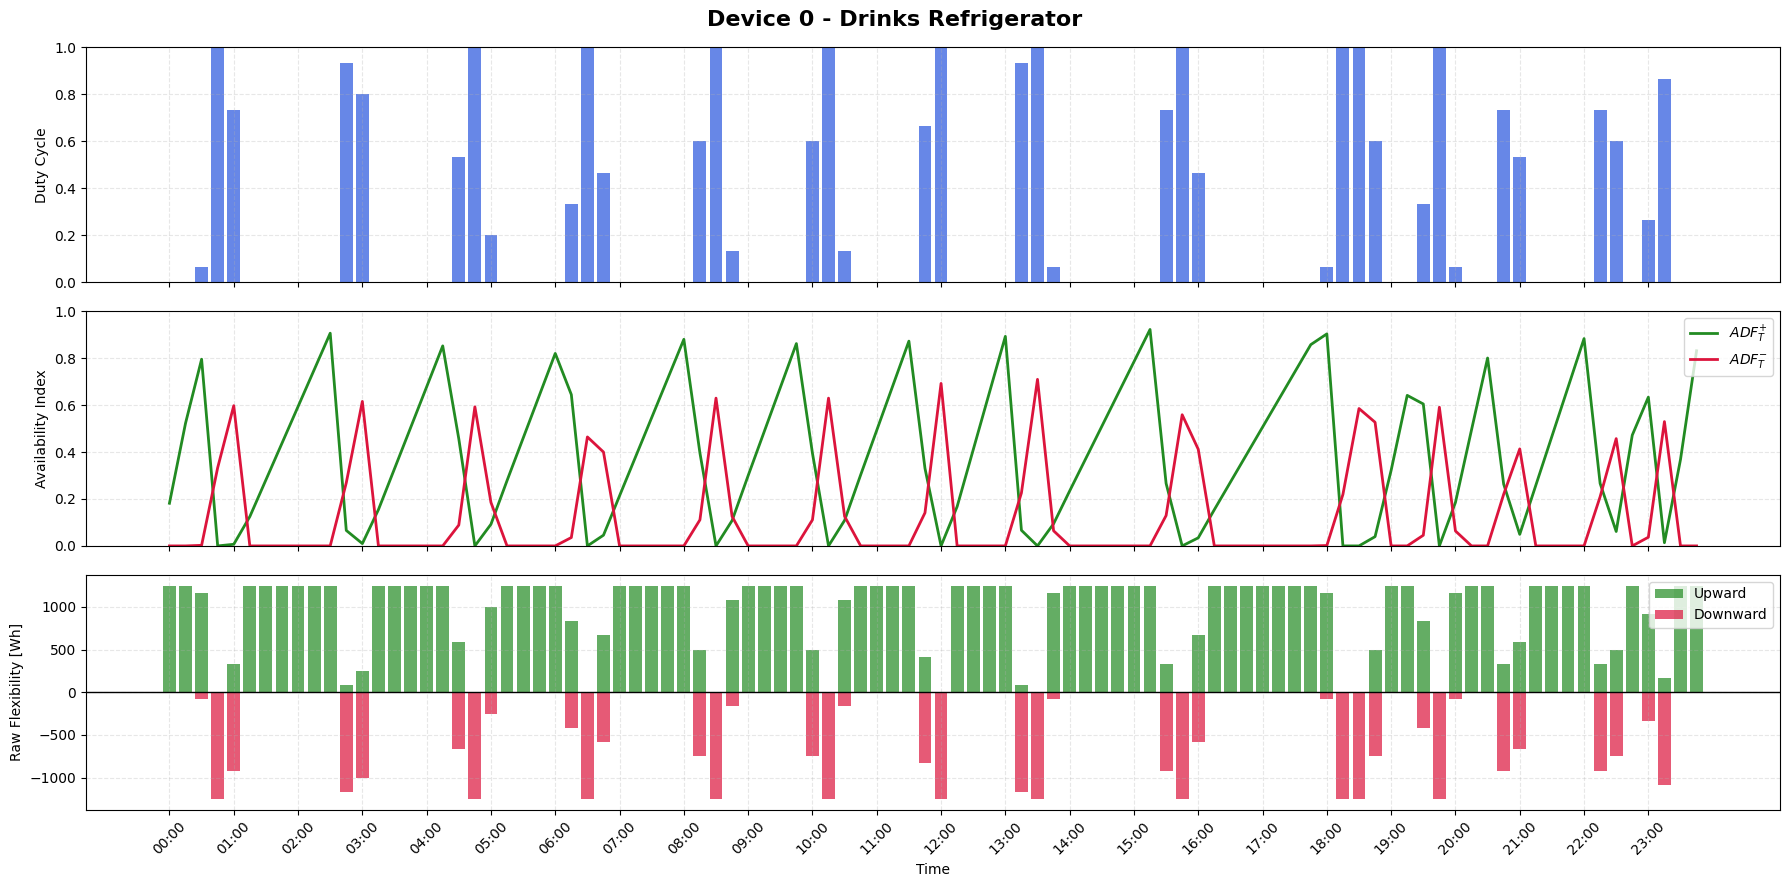

In [76]:
def plot_time_flex_device_summary(j, df=flexibility_15min_device):
    """
    Plots:
    1) Duty Cycle
    2) AI_T_up / AI_T_down
    3) RF_T_up_Wh / RF_T_down_Wh
    """

    dfj = df[df["appliance_j"] == j].copy()

    if dfj.empty:
        raise ValueError(f"No data found for appliance {j}")

    if dfj["Type"].iloc[0] != 2:
        print(f"Warning: appliance {j} is not time-flexible. Type={dfj['Type'].iloc[0]}")

    x = np.arange(len(dfj))
    labels = dfj["time"].astype(str).values

    fig, axes = plt.subplots(
        3, 1,
        figsize=(18, 9),
        sharex=True
    )

    title = f"Device {j}"
    if "appliance_name" in dfj.columns:
        title += f" - {dfj['appliance_name'].iloc[0]}"

    fig.suptitle(title, fontsize=16, fontweight="bold")

    # --------------------------------------------------
    # 1) Duty Cycle
    # --------------------------------------------------
    axes[0].bar(
        x,
        dfj["Duty_Cycle"],
        color="royalblue",
        alpha=0.8
    )

    axes[0].set_ylabel("Duty Cycle")
    axes[0].set_ylim(0, 1)
    axes[0].grid(True, linestyle="--", alpha=0.3)

    # --------------------------------------------------
    # 2) Availability Indices
    # --------------------------------------------------
    axes[1].plot(
        x,
        dfj["AI_T_up"],
        color="forestgreen",
        linewidth=2,
        label=r"$ADF_T^{+}$"
    )

    axes[1].plot(
        x,
        dfj["AI_T_down"],
        color="crimson",
        linewidth=2,
        label=r"$ADF_T^{-}$"
    )

    axes[1].set_ylabel("Availability Index")
    axes[1].set_ylim(0, 1)
    axes[1].legend(loc="upper right")
    axes[1].grid(True, linestyle="--", alpha=0.3)

    # --------------------------------------------------
    # 3) Raw Flexibility (Wh)
    # --------------------------------------------------
    axes[2].bar(
        x,
        dfj["RF_T_up_Wh"],
        color="forestgreen",
        alpha=0.7,
        label="Upward"
    )

    axes[2].bar(
        x,
        -dfj["RF_T_down_Wh"],
        color="crimson",
        alpha=0.7,
        label="Downward"
    )

    axes[2].axhline(0, color="black", linewidth=1)

    axes[2].set_ylabel("Raw Flexibility [Wh]")
    axes[2].legend(loc="upper right")
    axes[2].grid(True, linestyle="--", alpha=0.3)

    # --------------------------------------------------
    # X axis
    # --------------------------------------------------
    step = 4

    axes[2].set_xticks(x[::step])
    axes[2].set_xticklabels(labels[::step], rotation=45)
    axes[2].set_xlabel("Time")

    plt.tight_layout()
    plt.show()

plot_time_flex_device_summary(0, df=flexibility_15min_device)

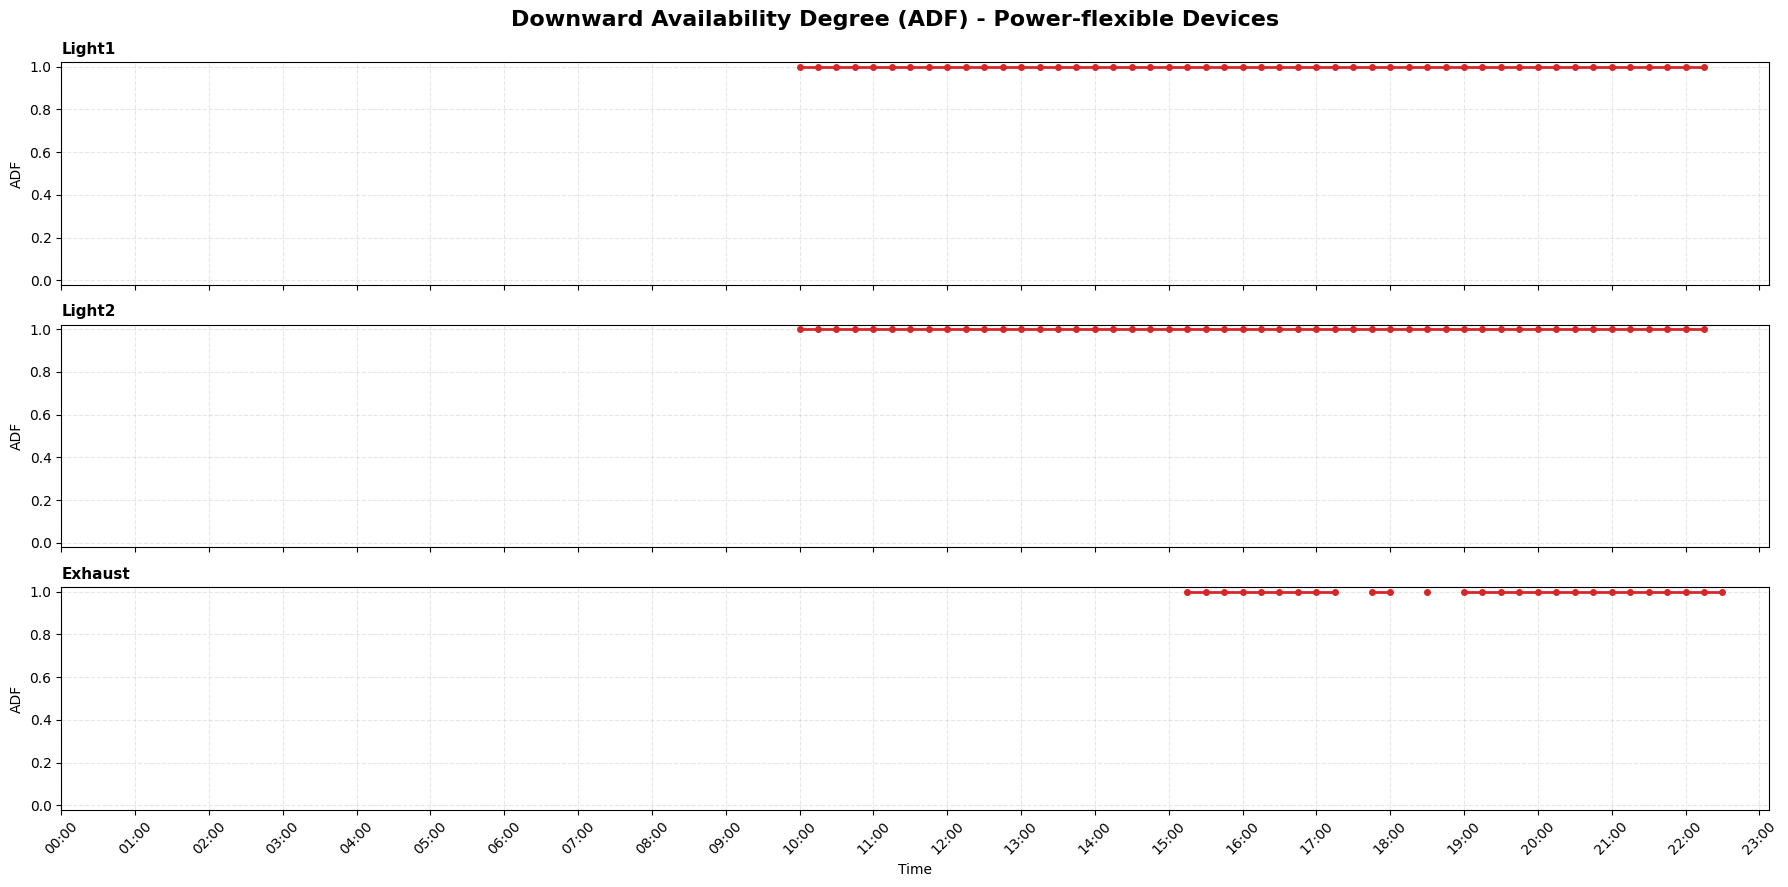

In [77]:
import matplotlib.pyplot as plt
import numpy as np


def plot_adf_p_lines(flexibility_15min_device):
    """
    One line plot per power-flexible device showing ADF_P_down over time.
    """

    df = flexibility_15min_device.copy()
    df = df[df["Type"] == 1].copy()

    if df.empty:
        print("No power-flexible devices found.")
        return

    devices = df["appliance_j"].unique()
    n = len(devices)

    fig, axes = plt.subplots(
        n,
        1,
        figsize=(18, max(3*n, 4)),
        sharex=True
    )

    if n == 1:
        axes = [axes]

    for ax, j in zip(axes, devices):

        dfj = (
            df[df["appliance_j"] == j]
            .sort_values("block")
        )

        x = np.arange(len(dfj))

        ax.plot(
            x,
            dfj["AI_P_down"],
            "-o",
            color="tab:red",
            linewidth=2,
            markersize=4
        )

        ax.set_ylim(-0.02, 1.02)
        ax.set_ylabel("ADF")

        ax.set_title(
            dfj["appliance_name"].iloc[0],
            loc="left",
            fontsize=11,
            fontweight="bold"
        )

        ax.grid(True, linestyle="--", alpha=0.3)

    labels = dfj["time"].astype(str).values
    step = max(1, len(labels)//24)

    axes[-1].set_xticks(x[::step])
    axes[-1].set_xticklabels(labels[::step], rotation=45)
    axes[-1].set_xlabel("Time")

    fig.suptitle(
        "Downward Availability Degree (ADF) - Power-flexible Devices",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()
plot_adf_p_lines(flexibility_15min_device)

# Planeamento Flex

In [79]:
def get_time_zone_from_block(k, block_size=BLOCK_SIZE):
    """
    0 -> 00:00 - 09:59
    1 -> 10:00 - 19:29
    2 -> 19:30 - 22:29
    3 -> 22:30 - 23:59
    """
    minute = k * block_size

    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3


def get_p_lim_k(k, block_size=BLOCK_SIZE):
    """
    Power limit [W] for block k.
    """

    tz = get_time_zone_from_block(k, block_size)

    if tz == 0:
        return 5000.0
    elif tz == 1:
        return 10000.0
    elif tz == 2:
        return 20000.0
    else:
        return 10000.0


def get_e_lim_k(k, block_size=BLOCK_SIZE):
    """
    Energy limit [Wh] for block k.
    """

    P_lim_k_W = get_p_lim_k(k, block_size)

    return P_lim_k_W * block_size / 60
    
P_lim = np.array([
    get_p_lim_k(k, BLOCK_SIZE)
    for k in range(N_BLOCKS)
])

E_lim = np.array([
    get_e_lim_k(k, BLOCK_SIZE)
    for k in range(N_BLOCKS)
])

def add_energy_columns(df, E_lim, block_size=15):
    df = df.copy()

    df["DC_base"] = df["Duty_Cycle"].fillna(0.0)
    df["Y_base"] = df["Y_base"].fillna(0.0)

    if "DC_rec" not in df.columns:
        df["DC_rec"] = df["DC_base"]

    if "Y_rec" not in df.columns:
        df["Y_rec"] = df["Y_base"]

    df["E_base_row_Wh"] = 0.0
    df["E_rec_row_Wh"] = 0.0

    mask_t = df["Type"] == 2
    mask_p = df["Type"] == 1
    mask_nf = df["Type"] == 0

    df.loc[mask_t, "E_base_row_Wh"] = (
        df.loc[mask_t, "Power_max_W"] *
        df.loc[mask_t, "DC_base"] *
        block_size / 60
    )

    df.loc[mask_t, "E_rec_row_Wh"] = (
        df.loc[mask_t, "Power_max_W"] *
        df.loc[mask_t, "DC_rec"] *
        block_size / 60
    )

    df.loc[mask_p, "E_base_row_Wh"] = (
        df.loc[mask_p, "Power_max_W"] *
        df.loc[mask_p, "Y_base"] *
        block_size / 60
    )

    df.loc[mask_p, "E_rec_row_Wh"] = (
        df.loc[mask_p, "Power_max_W"] *
        df.loc[mask_p, "Y_rec"] *
        block_size / 60
    )

    df.loc[mask_nf, "E_base_row_Wh"] = (
        df.loc[mask_nf, "Power_max_W"] *
        df.loc[mask_nf, "Duty_Cycle"].fillna(0.0) *
        block_size / 60
    )

    df.loc[mask_nf, "E_rec_row_Wh"] = df.loc[mask_nf, "E_base_row_Wh"]

    return df

def build_schedule_summary(df, E_lim, block_size=15, E_rlx_dict=None):
    df = add_energy_columns(df, E_lim, block_size)

    summary = (
        df.groupby(["block", "time"], as_index=False)
        .agg(
            E_base_Wh=("E_base_row_Wh", "sum"),
            E_rec_Wh=("E_rec_row_Wh", "sum")
        )
    )

    summary["E_lim_Wh"] = summary["block"].apply(
        lambda k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
    )

    summary["initial_violation_Wh"] = (
        summary["E_base_Wh"] - summary["E_lim_Wh"]
    ).clip(lower=0)

    summary["remaining_violation_Wh"] = (
        summary["E_rec_Wh"] - summary["E_lim_Wh"]
    ).clip(lower=0)

    summary["reduction_Wh"] = summary["E_base_Wh"] - summary["E_rec_Wh"]

    summary["P_base_W_equiv"] = summary["E_base_Wh"] * 60 / block_size
    summary["P_rec_W_equiv"] = summary["E_rec_Wh"] * 60 / block_size
    summary["P_lim_W_equiv"] = summary["E_lim_Wh"] * 60 / block_size

    if E_rlx_dict is not None:
        summary["E_rlx_Wh"] = summary["block"].map(E_rlx_dict)
    else:
        summary["E_rlx_Wh"] = np.nan

    return summary

### Greedy Algorithm

In [80]:
def greedy_algorithm(
    flexibility_15min_device,
    E_lim,
    block_size=15,
    y_step=0.10,
    ai_p_threshold=0.0,
    ai_t_threshold=0.0
):
    df = flexibility_15min_device.copy()

    # -------------------------
    # Base variables
    # -------------------------
    df["DC_base"] = df["Duty_Cycle"].fillna(0.0)

    df["n_on_base"] = np.where(
        df["Type"] == 2,
        np.rint(df["DC_base"] * block_size).astype(int),
        np.nan
    )

    df["n_on_rec"] = df["n_on_base"].copy()

    df["DC_rec"] = np.where(
        df["Type"] == 2,
        df["n_on_rec"] / block_size,
        df["DC_base"]
    )

    df["n_on_reduction"] = 0.0
    df["DC_reduction"] = 0.0

    df["Y_base"] = df["Y_base"].fillna(0.0)
    df["Y_rec"] = df["Y_base"].copy()
    df["Y_reduction"] = 0.0

    # -------------------------
    # Energy computation
    # -------------------------
    def update_energy_columns(df):
        df = df.copy()

        df["E_base_row_Wh"] = 0.0
        df["E_rec_row_Wh"] = 0.0

        mask_t = df["Type"] == 2
        mask_p = df["Type"] == 1
        mask_nf = df["Type"] == 0

        df.loc[mask_t, "E_base_row_Wh"] = (
            df.loc[mask_t, "Power_max_W"] *
            df.loc[mask_t, "n_on_base"] / 60
        )

        df.loc[mask_t, "E_rec_row_Wh"] = (
            df.loc[mask_t, "Power_max_W"] *
            df.loc[mask_t, "n_on_rec"] / 60
        )

        df.loc[mask_p, "E_base_row_Wh"] = (
            df.loc[mask_p, "Power_max_W"] *
            df.loc[mask_p, "Y_base"] *
            block_size / 60
        )

        df.loc[mask_p, "E_rec_row_Wh"] = (
            df.loc[mask_p, "Power_max_W"] *
            df.loc[mask_p, "Y_rec"] *
            block_size / 60
        )

        df.loc[mask_nf, "E_base_row_Wh"] = (
            df.loc[mask_nf, "Power_max_W"] *
            df.loc[mask_nf, "Duty_Cycle"].fillna(0.0) *
            block_size / 60
        )

        df.loc[mask_nf, "E_rec_row_Wh"] = df.loc[mask_nf, "E_base_row_Wh"]

        return df

    # -------------------------
    # Greedy loop
    # -------------------------
    for k in sorted(df["block"].unique()):

        E_lim_k_Wh = E_lim[k] if hasattr(E_lim, "__len__") else E_lim
        block_mask = df["block"] == k

        df = update_energy_columns(df)
        E_rec_Wh = df.loc[block_mask, "E_rec_row_Wh"].sum()

        # =========================
        # 1) POWER-FLEXIBLE FIRST
        # =========================
        if E_rec_Wh > E_lim_k_Wh:

            candidates_p = df[
                block_mask &
                (df["Type"] == 1) &
                (df["AI_P_down"] >= ai_p_threshold) &
                (df["RF_P_down_Wh"] > 0)
            ].sort_values(
                by="AI_P_down",
                ascending=False
            )

            for idx, row in candidates_p.iterrows():

                while E_rec_Wh > E_lim_k_Wh + 1e-6:

                    j = int(row["appliance_j"])
                    current_y = df.loc[idx, "Y_rec"]

                    if current_y <= Y_min[j] + 1e-9:
                        break

                    new_y = max(Y_min[j], current_y - y_step)
                    delta_y = current_y - new_y

                    df.loc[idx, "Y_rec"] = new_y
                    df.loc[idx, "Y_reduction"] += delta_y

                    df = update_energy_columns(df)
                    E_rec_Wh = df.loc[block_mask, "E_rec_row_Wh"].sum()

        # =========================
        # 2) TIME-FLEXIBLE SECOND
        # =========================
        if E_rec_Wh > E_lim_k_Wh:

            candidates_t = df[
                block_mask &
                (df["Type"] == 2) &
                (df["AI_T_down"] >= ai_t_threshold) &
                (df["RF_T_down_Wh"] > 0) &
                (df["n_on_rec"] > 0)
            ].sort_values(
                by="AI_T_down",
                ascending=False
            )

            for idx, row in candidates_t.iterrows():

                while E_rec_Wh > E_lim_k_Wh + 1e-6:

                    current_n = df.loc[idx, "n_on_rec"]

                    if current_n <= 0:
                        break

                    new_n = max(0, current_n - 1)
                    delta_n = current_n - new_n

                    df.loc[idx, "n_on_rec"] = new_n
                    df.loc[idx, "n_on_reduction"] += delta_n

                    df.loc[idx, "DC_rec"] = new_n / block_size
                    df.loc[idx, "DC_reduction"] = (
                        df.loc[idx, "DC_base"] - df.loc[idx, "DC_rec"]
                    )

                    df = update_energy_columns(df)
                    E_rec_Wh = df.loc[block_mask, "E_rec_row_Wh"].sum()

    # -------------------------
    # Final update
    # -------------------------
    df = update_energy_columns(df)

    df["DC_change"] = df["DC_rec"] - df["DC_base"]
    df["Y_change"] = df["Y_rec"] - df["Y_base"]

    # -------------------------
    # Summary
    # -------------------------
    summary = (
        df.groupby(["block", "time"], as_index=False)
        .agg(
            E_base_Wh=("E_base_row_Wh", "sum"),
            E_rec_Wh=("E_rec_row_Wh", "sum")
        )
    )

    summary["E_lim_Wh"] = summary["block"].apply(
        lambda k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
    )

    summary["initial_violation_Wh"] = (
        summary["E_base_Wh"] - summary["E_lim_Wh"]
    ).clip(lower=0)

    summary["remaining_violation_Wh"] = (
        summary["E_rec_Wh"] - summary["E_lim_Wh"]
    ).clip(lower=0)

    summary["reduction_Wh"] = summary["E_base_Wh"] - summary["E_rec_Wh"]

    summary["E_rlx_Wh"] = np.nan

    return df, summary
schedule_15min_device, greedy_summary = greedy_algorithm(
    flexibility_15min_device=flexibility_15min_device,
    E_lim=E_lim,
    block_size=BLOCK_SIZE,
    y_step=0.10,
    ai_p_threshold=0.0,
    ai_t_threshold=0.0
)

### Optimization Algorithm

In [84]:
import pyomo.environ as pe
import numpy as np
import pandas as pd


def optimization_algorithm(
    flexibility_15min_device,
    E_lim,
    Y_min,
    Y_max,
    block_size=15,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="glpk",
    epsilon_P = 0.1
):
    df = flexibility_15min_device.copy()

    # -------------------------
    # Sets
    # -------------------------
    blocks = sorted(df["block"].unique())
    J_T = sorted(df.loc[df["Type"] == 2, "appliance_j"].unique())
    J_P = sorted(df.loc[df["Type"] == 1, "appliance_j"].unique())
    J_NF = sorted(df.loc[df["Type"] == 0, "appliance_j"].unique())

    # -------------------------
    # Helper function
    # -------------------------
    def get_val(j, k, col, default=0.0):
        s = df.loc[
            (df["appliance_j"] == j) &
            (df["block"] == k),
            col
        ]

        if s.empty or pd.isna(s.iloc[0]):
            return default

        return float(s.iloc[0])

    # -------------------------
    # Parameters
    # -------------------------
    Pmax = {
        j: float(df.loc[df["appliance_j"] == j, "Power_max_W"].iloc[0])
        for j in df["appliance_j"].unique()
    }

    DC_base = {
        (j, k): get_val(j, k, "Duty_Cycle", 0.0)
        for j in J_T for k in blocks
    }

    n_base = {
        (j, k): int(round(DC_base[j, k] * block_size))
        for j in J_T for k in blocks
    }

    Y_base = {
        (j, k): get_val(j, k, "Y_base", 0.0)
        for j in J_P for k in blocks
    }

    ADF_T = {
        (j, k): get_val(j, k, "AI_T_down", 0.0)
        for j in J_T for k in blocks
    }

    ADF_P = {
        (j, k): get_val(j, k, "AI_P_down", 0.0)
        for j in J_P for k in blocks
    }

    E_NF = {}
    for k in blocks:
        e = 0.0
        for j in J_NF:
            dc_nf = get_val(j, k, "Duty_Cycle", 0.0)
            e += Pmax[j] * dc_nf * block_size / 60
        E_NF[k] = e

    E_lim_dict = {
        k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
        for k in blocks
    }

    # -------------------------
    # Model
    # -------------------------
    m = pe.ConcreteModel()

    m.K = pe.Set(initialize=blocks)
    m.JT = pe.Set(initialize=J_T)
    m.JP = pe.Set(initialize=J_P)

    # -------------------------
    # Decision variables
    # -------------------------
    # Number of ON minutes in each block
    m.n_on = pe.Var(
        m.JT,
        m.K,
        domain=pe.NonNegativeIntegers,
        bounds=(0, block_size)
    )

    # Power fraction for power-flexible devices
    m.Y_rec = pe.Var(
        m.JP,
        m.K,
        bounds=(0, 1)
    )

    # Energy relaxation
    m.E_rlx = pe.Var(
        m.K,
        bounds=(0, None)
    )

    # Absolute deviation variables
    m.dN = pe.Var(
        m.JT,
        m.K,
        bounds=(0, None)
    )

    m.dY = pe.Var(
        m.JP,
        m.K,
        bounds=(0, None)
    )

    # -------------------------
    # Energy limit constraint
    # -------------------------
    def energy_limit_rule(m, k):

        E_time = sum(
            Pmax[j] * m.n_on[j, k] / 60
            for j in m.JT
        )

        E_power = sum(
            Pmax[j] * m.Y_rec[j, k] * block_size / 60
            for j in m.JP
        )

        return E_time + E_power + E_NF[k] <= E_lim_dict[k] + m.E_rlx[k]

    m.energy_limit = pe.Constraint(
        m.K,
        rule=energy_limit_rule
    )

    # -------------------------
    # Daily conservation for time-flexible devices
    # -------------------------
    def daily_conservation_rule(m, j):
        return sum(m.n_on[j, k] for k in m.K) == sum(n_base[j, k] for k in m.K)

    m.daily_conservation = pe.Constraint(
        m.JT,
        rule=daily_conservation_rule
    )

    # -------------------------
    # Power-flexible bounds
    # -------------------------
    def y_min_rule(m, j, k):
        if Y_base[j, k] <= 1e-9:
            return m.Y_rec[j, k] == 0
        return m.Y_rec[j, k] >= Y_min[j]

    def y_max_rule(m, j, k):
        if Y_base[j, k] <= 1e-9:
            return pe.Constraint.Skip
        return m.Y_rec[j, k] <= Y_max[j]

    m.y_min_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_min_rule
    )

    m.y_max_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_max_rule
    )

    # -------------------------
    # Absolute value linearization for n_on
    # -------------------------
    def dN_pos_rule(m, j, k):
        return m.dN[j, k] >= m.n_on[j, k] - n_base[j, k]

    def dN_neg_rule(m, j, k):
        return m.dN[j, k] >= n_base[j, k] - m.n_on[j, k]

    m.dN_pos = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_pos_rule
    )

    m.dN_neg = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_neg_rule
    )

    # -------------------------
    # Absolute value linearization for Y
    # -------------------------
    def dY_pos_rule(m, j, k):
        return m.dY[j, k] >= m.Y_rec[j, k] - Y_base[j, k]

    def dY_neg_rule(m, j, k):
        return m.dY[j, k] >= Y_base[j, k] - m.Y_rec[j, k]

    m.dY_pos = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_pos_rule
    )

    m.dY_neg = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_neg_rule
    )

    # -------------------------
    # Objective function
    # -------------------------

    m.obj = pe.Objective(
        expr=
            lambda_slack * sum(
                m.E_rlx[k]
                for k in m.K
            )
            +
            lambda_T * sum(
                (1 - ADF_T[j, k]) * m.dN[j, k]
                for j in m.JT
                for k in m.K
            )
            +
            lambda_P * sum(
                (epsilon_P + (1 - ADF_P[j, k])) * m.dY[j, k]
                for j in m.JP
                for k in m.K
            ),
        sense=pe.minimize
    )

    # -------------------------
    # Solve
    # -------------------------
    solver = pe.SolverFactory(solver_name)
    result = solver.solve(m, tee=False)

    # -------------------------
    # Extract outputs
    # -------------------------
    out = df.copy()

    out["DC_base"] = out["Duty_Cycle"].fillna(0.0)
    out["Y_base"] = out["Y_base"].fillna(0.0)

    out["n_on_base"] = np.nan
    out["n_on_rec"] = np.nan

    out["DC_rec"] = out["DC_base"]
    out["Y_rec"] = out["Y_base"]

    for j in J_T:
        for k in blocks:
            mask = (out["appliance_j"] == j) & (out["block"] == k)

            n_rec = pe.value(m.n_on[j, k])

            out.loc[mask, "n_on_base"] = n_base[j, k]
            out.loc[mask, "n_on_rec"] = n_rec
            out.loc[mask, "DC_rec"] = n_rec / block_size

    for j in J_P:
        for k in blocks:
            mask = (out["appliance_j"] == j) & (out["block"] == k)

            out.loc[mask, "Y_rec"] = pe.value(m.Y_rec[j, k])

    out["DC_change"] = out["DC_rec"] - out["DC_base"]
    out["Y_change"] = out["Y_rec"] - out["Y_base"]

    if "add_energy_columns" in globals():
        out = add_energy_columns(out, E_lim, block_size)

    E_rlx_dict = {
        k: pe.value(m.E_rlx[k])
        for k in blocks
    }

    summary = build_schedule_summary(
            out,
            E_lim,
            block_size,
            E_rlx_dict=E_rlx_dict)



    return out, summary, m, result

optimization_15min_device, optimization_summary, model, result = optimization_algorithm(
    flexibility_15min_device=flexibility_15min_device,
    E_lim=E_lim, 
    Y_min=Y_min,
    Y_max=Y_max,
    block_size=BLOCK_SIZE,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="glpk",
    epsilon_P=0.1
    )

### Optimização com horizonte por Timezone 

In [85]:
import pyomo.environ as pe
import numpy as np
import pandas as pd


def optimization_algorithm(
    flexibility_15min_device,
    E_lim,
    Y_min,
    Y_max,
    block_size=15,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="glpk",
    epsilon_P = 0.1
):
    df = flexibility_15min_device.copy()

    # -------------------------
    # Sets
    # -------------------------
    blocks = sorted(df["block"].unique())
    J_T = sorted(df.loc[df["Type"] == 2, "appliance_j"].unique())
    J_P = sorted(df.loc[df["Type"] == 1, "appliance_j"].unique())
    J_NF = sorted(df.loc[df["Type"] == 0, "appliance_j"].unique())

    # -------------------------
    # Helper function
    # -------------------------
    def get_val(j, k, col, default=0.0):
        s = df.loc[
            (df["appliance_j"] == j) &
            (df["block"] == k),
            col
        ]

        if s.empty or pd.isna(s.iloc[0]):
            return default

        return float(s.iloc[0])

    # -------------------------
    # Parameters
    # -------------------------
    Pmax = {
        j: float(df.loc[df["appliance_j"] == j, "Power_max_W"].iloc[0])
        for j in df["appliance_j"].unique()
    }

    DC_base = {
        (j, k): get_val(j, k, "Duty_Cycle", 0.0)
        for j in J_T for k in blocks
    }

    n_base = {
        (j, k): int(round(DC_base[j, k] * block_size))
        for j in J_T for k in blocks
    }

    Y_base = {
        (j, k): get_val(j, k, "Y_base", 0.0)
        for j in J_P for k in blocks
    }

    ADF_T = {
        (j, k): get_val(j, k, "AI_T_down", 0.0)
        for j in J_T for k in blocks
    }

    ADF_P = {
        (j, k): get_val(j, k, "AI_P_down", 0.0)
        for j in J_P for k in blocks
    }

    E_NF = {}
    for k in blocks:
        e = 0.0
        for j in J_NF:
            dc_nf = get_val(j, k, "Duty_Cycle", 0.0)
            e += Pmax[j] * dc_nf * block_size / 60
        E_NF[k] = e

    E_lim_dict = {
        k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
        for k in blocks
    }

    # -------------------------
    # Model
    # -------------------------
    m = pe.ConcreteModel()

    m.K = pe.Set(initialize=blocks)
    m.JT = pe.Set(initialize=J_T)
    m.JP = pe.Set(initialize=J_P)

    # -------------------------
    # Decision variables
    # -------------------------
    # Number of ON minutes in each block
    m.n_on = pe.Var(
        m.JT,
        m.K,
        domain=pe.NonNegativeIntegers,
        bounds=(0, block_size)
    )

    # Power fraction for power-flexible devices
    m.Y_rec = pe.Var(
        m.JP,
        m.K,
        bounds=(0, 1)
    )

    # Energy relaxation
    m.E_rlx = pe.Var(
        m.K,
        bounds=(0, None)
    )

    # Absolute deviation variables
    m.dN = pe.Var(
        m.JT,
        m.K,
        bounds=(0, None)
    )

    m.dY = pe.Var(
        m.JP,
        m.K,
        bounds=(0, None)
    )

    # -------------------------
    # Energy limit constraint
    # -------------------------
    def energy_limit_rule(m, k):

        E_time = sum(
            Pmax[j] * m.n_on[j, k] / 60
            for j in m.JT
        )

        E_power = sum(
            Pmax[j] * m.Y_rec[j, k] * block_size / 60
            for j in m.JP
        )

        return E_time + E_power + E_NF[k] <= E_lim_dict[k] + m.E_rlx[k]

    m.energy_limit = pe.Constraint(
        m.K,
        rule=energy_limit_rule
    )
    
    # -------------------------
    # Time-zone compensation constraints
    # -------------------------

    time_zones = sorted(set(
        get_time_zone_from_block(k, block_size)
        for k in blocks
    ))

    for j in J_T:

        for z in time_zones:

            zone_blocks = [
                k for k in blocks
                if get_time_zone_from_block(k, block_size) == z
            ]

            if len(zone_blocks) == 0:
                continue

            cname = f"timezone_conservation_j{j}_z{z}"

            m.add_component(
                cname,
                pe.Constraint(
                    expr=sum(m.n_on[j, k] for k in zone_blocks)
                    ==
                    sum(n_base[j, k] for k in zone_blocks)
                )
            )

    # -------------------------
    # Power-flexible bounds
    # -------------------------
    def y_min_rule(m, j, k):
        if Y_base[j, k] <= 1e-9:
            return m.Y_rec[j, k] == 0
        return m.Y_rec[j, k] >= Y_min[j]

    def y_max_rule(m, j, k):
        if Y_base[j, k] <= 1e-9:
            return pe.Constraint.Skip
        return m.Y_rec[j, k] <= Y_max[j]

    m.y_min_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_min_rule
    )

    m.y_max_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_max_rule
    )

    # -------------------------
    # Absolute value linearization for n_on
    # -------------------------
    def dN_pos_rule(m, j, k):
        return m.dN[j, k] >= m.n_on[j, k] - n_base[j, k]

    def dN_neg_rule(m, j, k):
        return m.dN[j, k] >= n_base[j, k] - m.n_on[j, k]

    m.dN_pos = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_pos_rule
    )

    m.dN_neg = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_neg_rule
    )

    # -------------------------
    # Absolute value linearization for Y
    # -------------------------
    def dY_pos_rule(m, j, k):
        return m.dY[j, k] >= m.Y_rec[j, k] - Y_base[j, k]

    def dY_neg_rule(m, j, k):
        return m.dY[j, k] >= Y_base[j, k] - m.Y_rec[j, k]

    m.dY_pos = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_pos_rule
    )

    m.dY_neg = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_neg_rule
    )

    # -------------------------
    # Objective function
    # -------------------------
    m.obj = pe.Objective(
        expr=
        lambda_slack * sum(
            m.E_rlx[k]
            for k in m.K
        )
        +
        lambda_T * sum(
            (1 - ADF_T[j, k]) * m.dN[j, k]
            for j in m.JT for k in m.K
        )
        +
        lambda_P * sum(
            (epsilon_P + (1 - ADF_P[j, k])) * m.dY[j, k]
            for j in m.JP for k in m.K
        ),
        sense=pe.minimize
    )

    # -------------------------
    # Solve
    # -------------------------
    solver = pe.SolverFactory(solver_name)
    result = solver.solve(m, tee=False)

    # -------------------------
    # Extract outputs
    # -------------------------
    out = df.copy()

    out["DC_base"] = out["Duty_Cycle"].fillna(0.0)
    out["Y_base"] = out["Y_base"].fillna(0.0)

    out["n_on_base"] = np.nan
    out["n_on_rec"] = np.nan

    out["DC_rec"] = out["DC_base"]
    out["Y_rec"] = out["Y_base"]

    for j in J_T:
        for k in blocks:
            mask = (out["appliance_j"] == j) & (out["block"] == k)

            n_rec = pe.value(m.n_on[j, k])

            out.loc[mask, "n_on_base"] = n_base[j, k]
            out.loc[mask, "n_on_rec"] = n_rec
            out.loc[mask, "DC_rec"] = n_rec / block_size

    for j in J_P:
        for k in blocks:
            mask = (out["appliance_j"] == j) & (out["block"] == k)

            out.loc[mask, "Y_rec"] = pe.value(m.Y_rec[j, k])

    out["DC_change"] = out["DC_rec"] - out["DC_base"]
    out["Y_change"] = out["Y_rec"] - out["Y_base"]

    if "add_energy_columns" in globals():
        out = add_energy_columns(out, E_lim, block_size)

    E_rlx_dict = {
        k: pe.value(m.E_rlx[k])
        for k in blocks
    }

    summary = build_schedule_summary(
            out,
            E_lim,
            block_size,
            E_rlx_dict=E_rlx_dict)



    return out, summary, m, result

optimization_timezone_horizon_15min_device, optimization_timezone_horizon, model2, result2 = optimization_algorithm(
    flexibility_15min_device=flexibility_15min_device,
    E_lim=E_lim, 
    Y_min=Y_min,
    Y_max=Y_max,
    block_size=BLOCK_SIZE,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="glpk",
    epsilon_P=0.1
    )

### Plots/Métricas

In [86]:
import matplotlib.pyplot as plt
import numpy as np

def plot_schedule(summary, title="Scheduling Results"):
    """
    Plot:
        - Baseline energy
        - Scheduled energy
        - Energy limit

    Expected columns:
        time
        E_base_Wh
        E_rec_Wh
        E_lim_Wh
    """

    x = np.arange(len(summary))
    labels = summary["time"].astype(str).values

    fig, ax = plt.subplots(figsize=(18,5))

    # Baseline
    ax.plot(
        x,
        summary["E_base_Wh"],
        linewidth=2.5,
        color="royalblue",
        label="Baseline"
    )

    # Scheduled
    ax.plot(
        x,
        summary["E_rec_Wh"],
        linewidth=2.5,
        color="forestgreen",
        label="Scheduled"
    )

    # Energy limit
    ax.plot(
        x,
        summary["E_lim_Wh"],
        "--",
        linewidth=2,
        color="crimson",
        label="Energy limit"
    )

    # Highlight violations
    ax.fill_between(
        x,
        summary["E_base_Wh"],
        summary["E_lim_Wh"],
        where=summary["E_base_Wh"] > summary["E_lim_Wh"],
        interpolate=True,
        color="red",
        alpha=0.20,
        label="Baseline violation"
    )

    ax.fill_between(
        x,
        summary["E_rec_Wh"],
        summary["E_lim_Wh"],
        where=summary["E_rec_Wh"] > summary["E_lim_Wh"],
        interpolate=True,
        color="orange",
        alpha=0.25,
        label="Remaining violation"
    )

    ax.set_ylabel("Energy [Wh]")
    ax.set_xlabel("Time")
    ax.set_title(title, fontsize=15, fontweight="bold")

    ax.grid(True, linestyle="--", alpha=0.3)

    step = max(1, len(summary)//24)
    ax.set_xticks(x[::step])
    ax.set_xticklabels(labels[::step], rotation=45)

    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

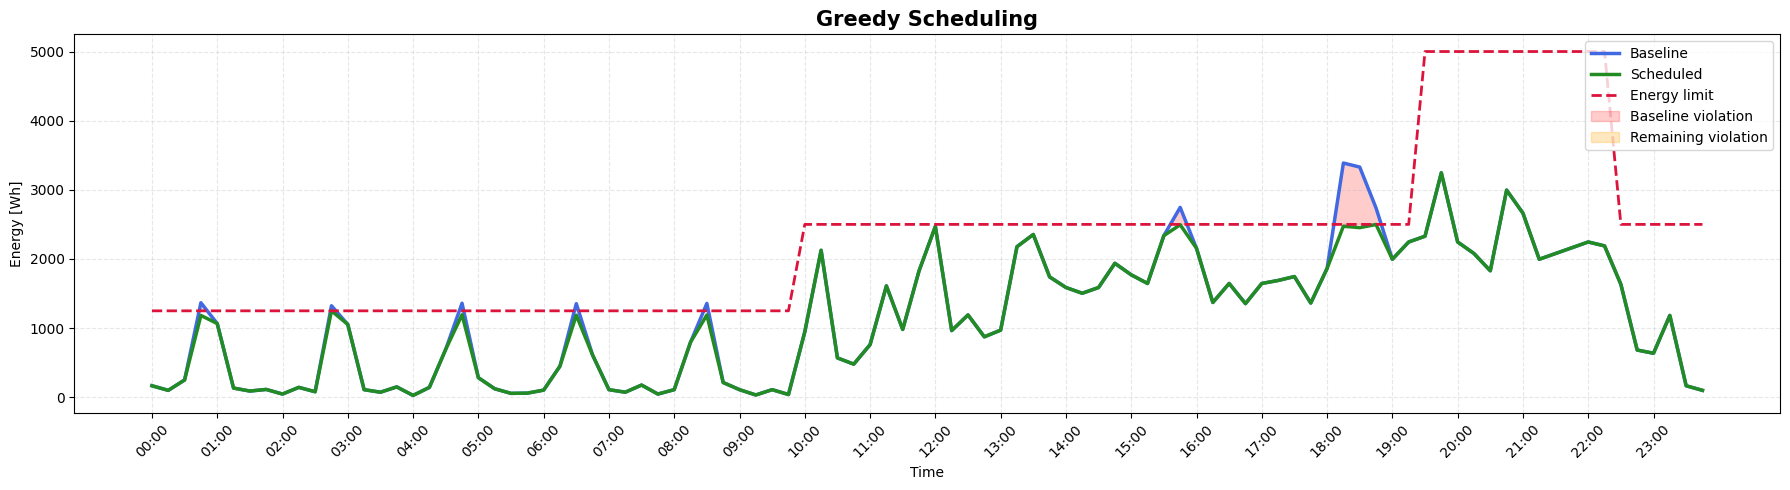

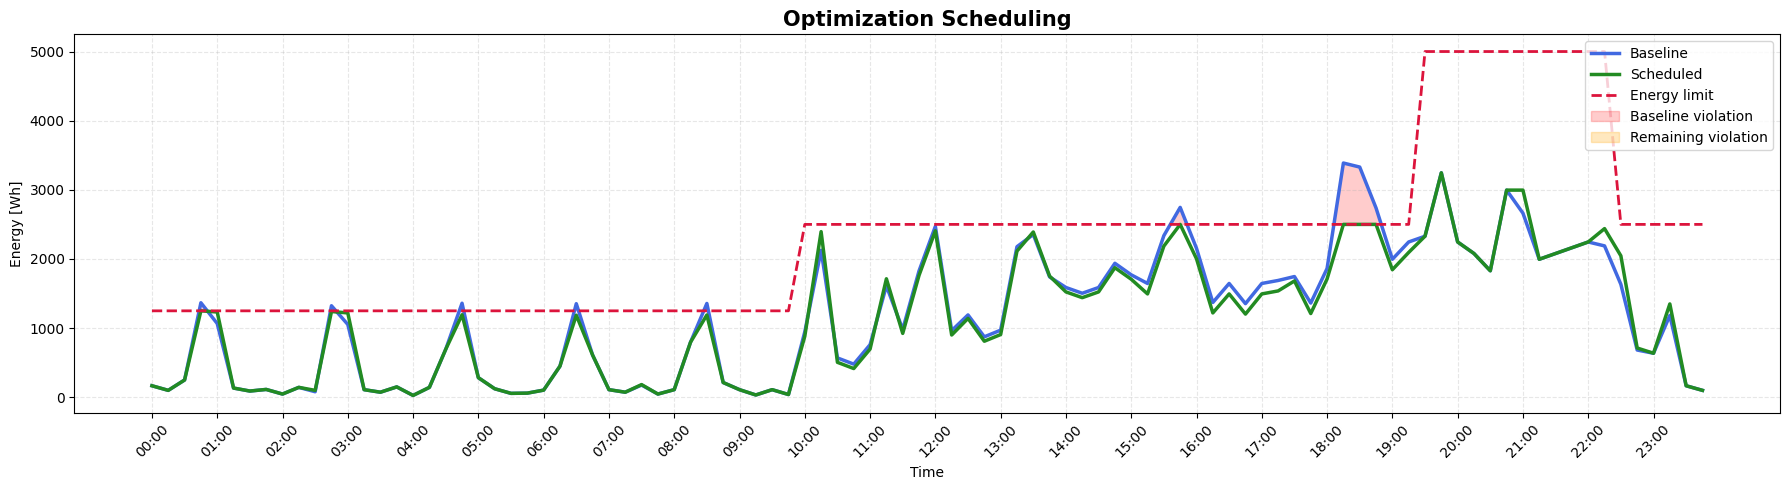

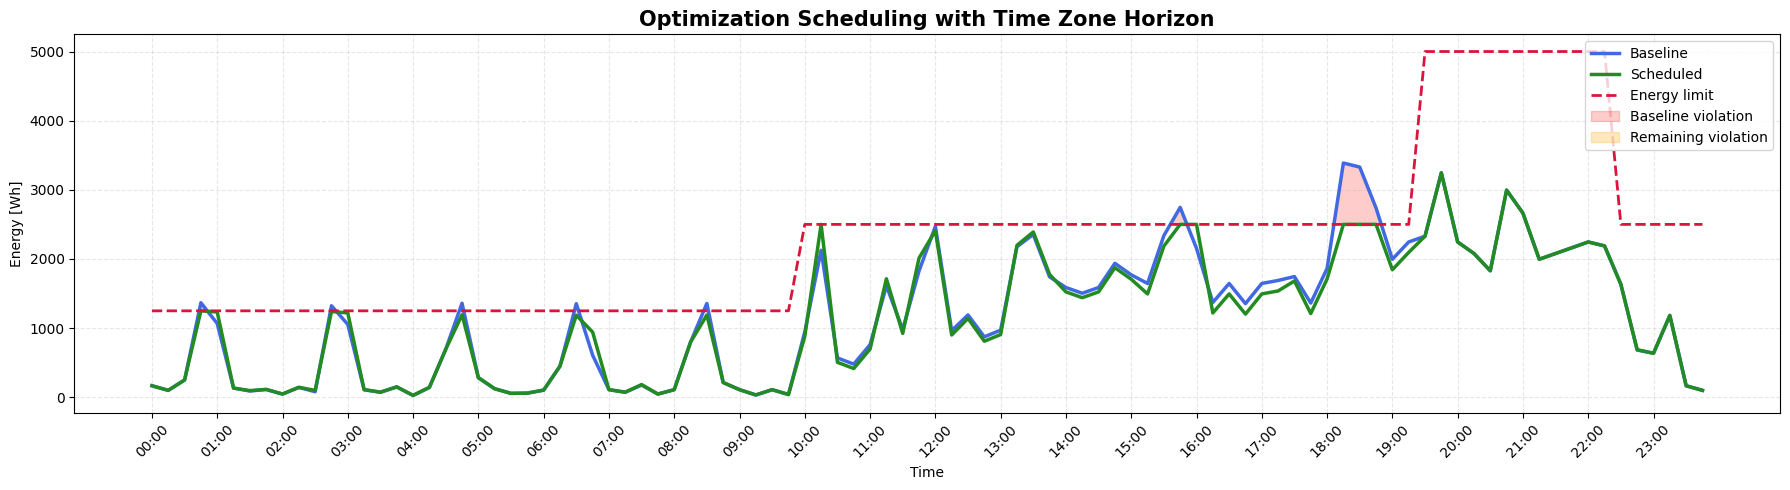

In [61]:
plot_schedule(
    greedy_summary,
    title="Greedy Scheduling"
)
plot_schedule(
    optimization_summary,
    title="Optimization Scheduling"
)
plot_schedule(
    optimization_timezone_horizon,
    title="Optimization Scheduling with Time Zone Horizon"
)

In [87]:
import matplotlib.pyplot as plt
import numpy as np


def plot_time_flexible_activation_heatmap(
    schedule_device,
    title="Time-flexible Scheduling Changes",
    block_size=15
):
    """
    Heatmap for time-flexible devices only.

    Value:
        Δn_on = n_on_rec - n_on_base

    Units:
        minutes ON changed within the block
    """

    df = schedule_device.copy()
    df = df[df["Type"] == 2].copy()

    if df.empty:
        print("No time-flexible devices found.")
        return

    if "n_on_base" not in df.columns:
        df["n_on_base"] = np.rint(df["DC_base"] * block_size)

    if "n_on_rec" not in df.columns:
        df["n_on_rec"] = np.rint(df["DC_rec"] * block_size)

    df["delta_n_on"] = df["n_on_rec"] - df["n_on_base"]

    heat = df.pivot_table(
        index="appliance_name",
        columns="time",
        values="delta_n_on",
        aggfunc="sum",
        fill_value=0
    )

    heat = heat.loc[np.abs(heat).sum(axis=1) > 1e-6]

    if heat.empty:
        print("No time-flexible scheduling changes.")
        return

    vmax = max(1, np.max(np.abs(heat.values)))

    fig, ax = plt.subplots(figsize=(18, max(5, len(heat) * 0.45)))

    im = ax.imshow(
        heat.values,
        aspect="auto",
        cmap="coolwarm",
        interpolation="nearest",
        vmin=-vmax,
        vmax=vmax
    )

    ax.set_yticks(np.arange(len(heat.index)))
    ax.set_yticklabels(heat.index)

    step = max(1, heat.shape[1] // 24)
    ax.set_xticks(np.arange(0, heat.shape[1], step))
    ax.set_xticklabels(heat.columns[::step], rotation=45, ha="right")

    ax.set_xlabel("Time")
    ax.set_ylabel("Time-flexible device")
    ax.set_title(title, fontsize=15, fontweight="bold")

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\Delta n_{on}$ [min/block]")

    plt.tight_layout()
    plt.show()


def plot_power_flexible_y_heatmap(
    schedule_device,
    title="Power-flexible Scheduling Changes"
):
    """
    Heatmap for power-flexible devices only.

    Value:
        ΔY = Y_rec - Y_base

    Units:
        power fraction change
    """

    df = schedule_device.copy()
    df = df[df["Type"] == 1].copy()

    if df.empty:
        print("No power-flexible devices found.")
        return

    df["delta_Y"] = df["Y_rec"] - df["Y_base"]

    heat = df.pivot_table(
        index="appliance_name",
        columns="time",
        values="delta_Y",
        aggfunc="sum",
        fill_value=0
    )

    heat = heat.loc[np.abs(heat).sum(axis=1) > 1e-6]

    if heat.empty:
        print("No power-flexible scheduling changes.")
        return

    vmax = max(0.1, np.max(np.abs(heat.values)))

    fig, ax = plt.subplots(figsize=(18, max(4, len(heat) * 0.7)))

    im = ax.imshow(
        heat.values,
        aspect="auto",
        cmap="coolwarm",
        interpolation="nearest",
        vmin=-vmax,
        vmax=vmax
    )

    ax.set_yticks(np.arange(len(heat.index)))
    ax.set_yticklabels(heat.index)

    step = max(1, heat.shape[1] // 24)
    ax.set_xticks(np.arange(0, heat.shape[1], step))
    ax.set_xticklabels(heat.columns[::step], rotation=45, ha="right")

    ax.set_xlabel("Time")
    ax.set_ylabel("Power-flexible device")
    ax.set_title(title, fontsize=15, fontweight="bold")

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\Delta Y$")

    plt.tight_layout()
    plt.show()

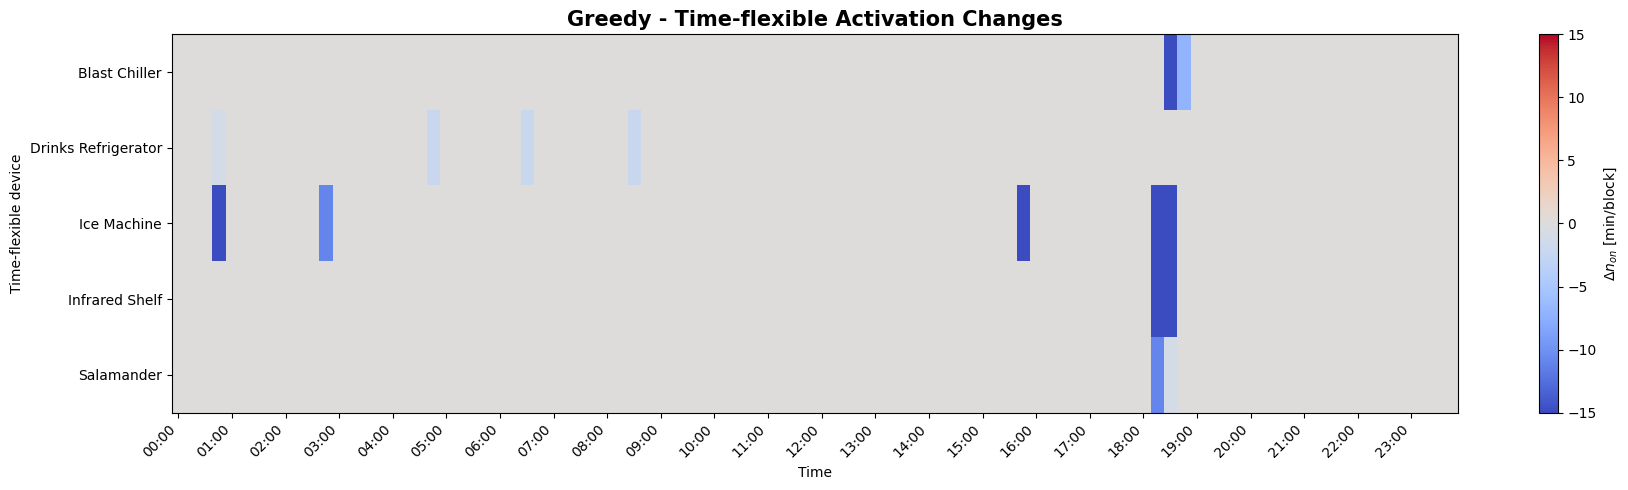

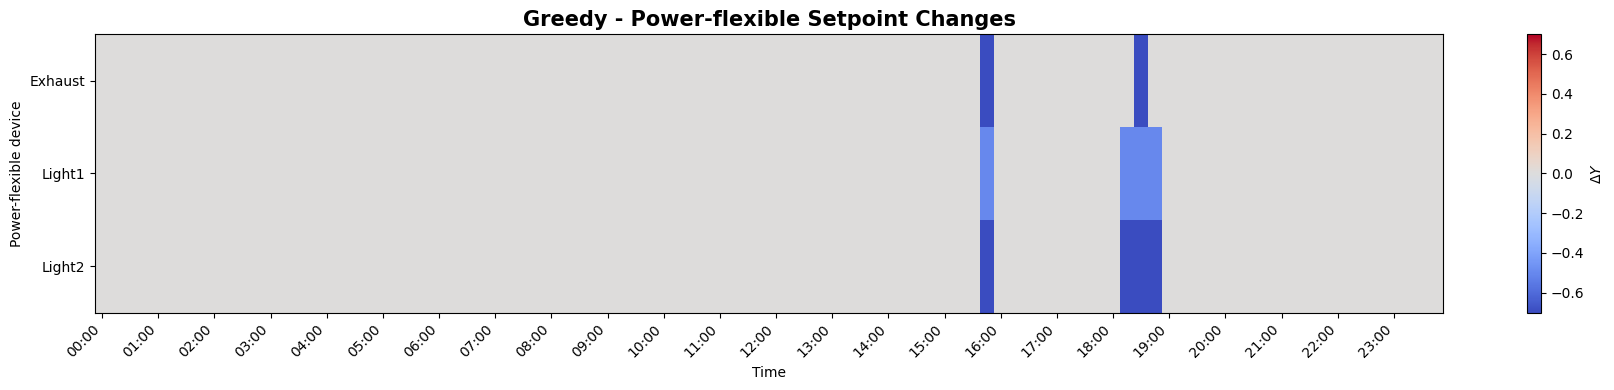

In [91]:
plot_time_flexible_activation_heatmap(
    schedule_15min_device,
    title="Greedy - Time-flexible Activation Changes",
    block_size=BLOCK_SIZE
)

plot_power_flexible_y_heatmap(
    schedule_15min_device,
    title="Greedy - Power-flexible Setpoint Changes"
)

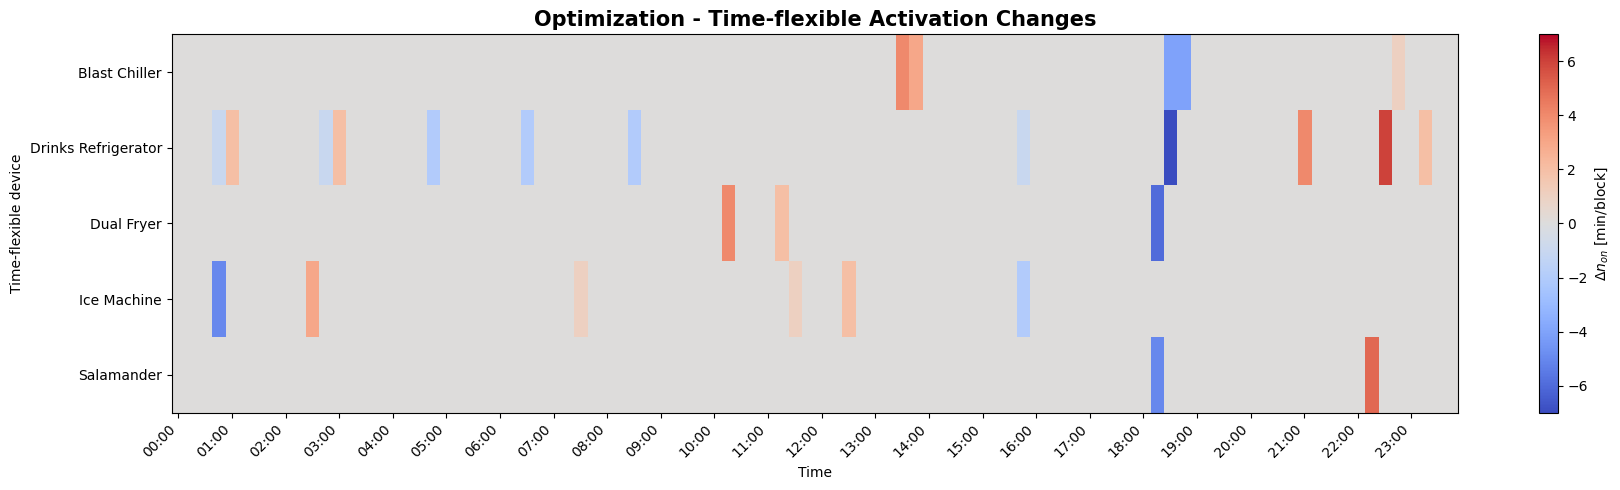

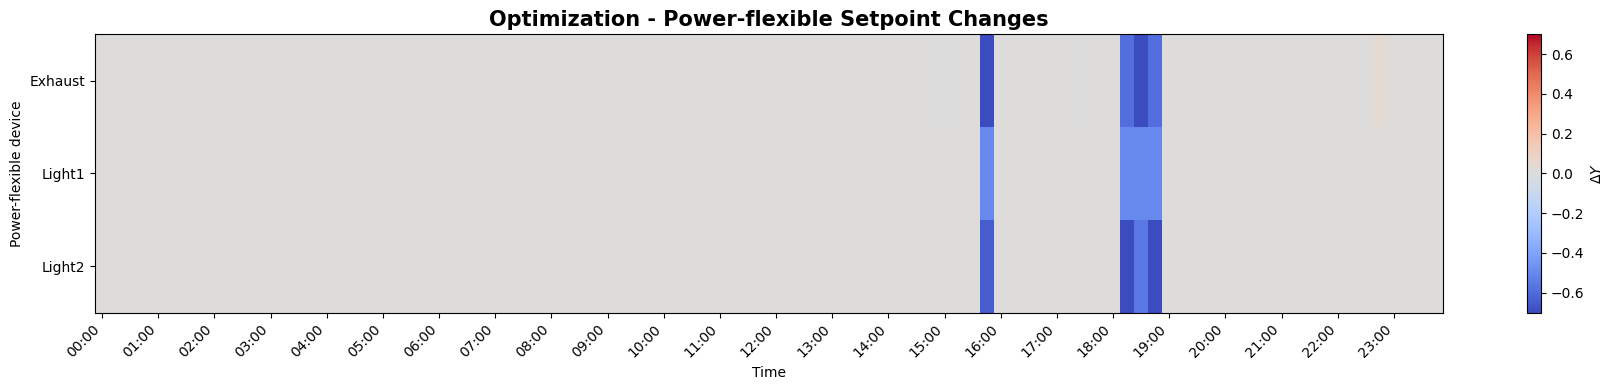

In [92]:
plot_time_flexible_activation_heatmap(
    optimization_15min_device,
    title="Optimization - Time-flexible Activation Changes",
    block_size=BLOCK_SIZE
)

plot_power_flexible_y_heatmap(
    optimization_15min_device,
    title="Optimization - Power-flexible Setpoint Changes"
)

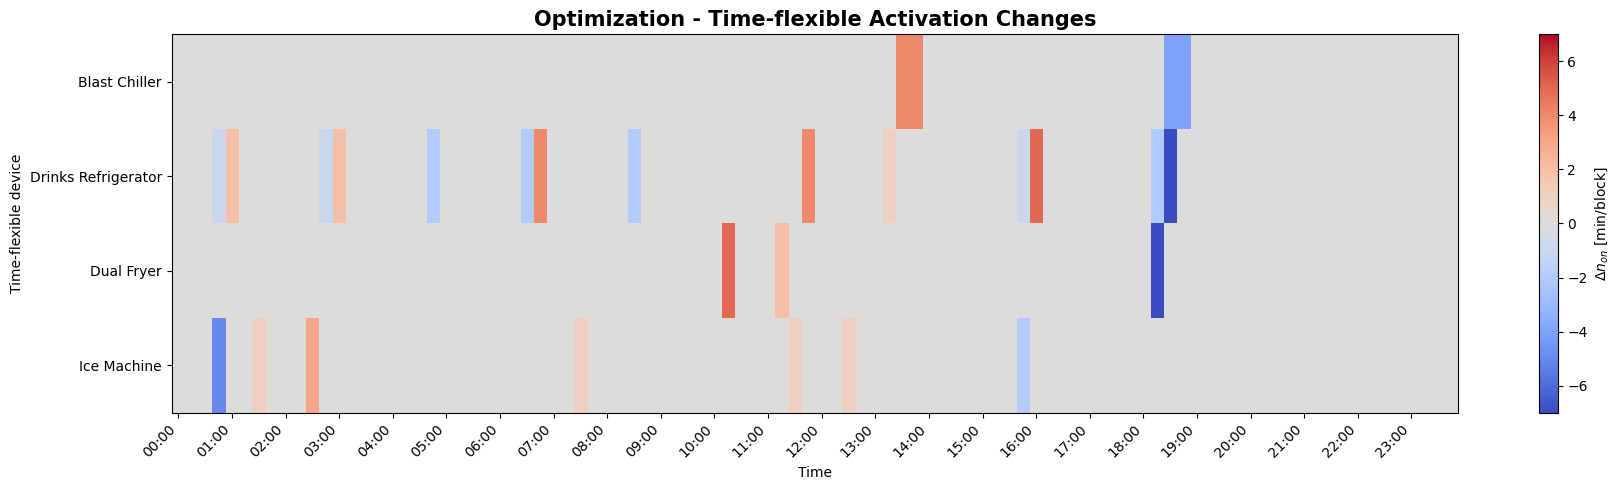

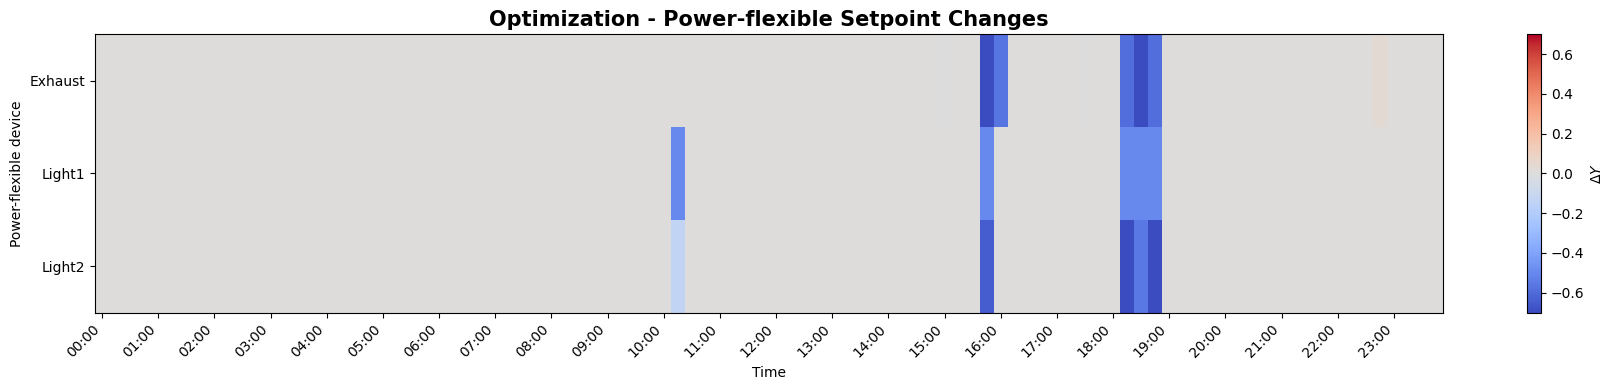

In [89]:
plot_time_flexible_activation_heatmap(
    optimization_timezone_horizon_15min_device,
    title="Optimization - Time-flexible Activation Changes",
    block_size=BLOCK_SIZE
)
plot_power_flexible_y_heatmap(
    optimization_timezone_horizon_15min_device,
    title="Optimization - Power-flexible Setpoint Changes"
)